# Per-fish and per-electrode-pair gains of my model (4-fish recordings, Kaden masks)

**Question.** My model gives, for each fish as the emitter, the voltage on each of the 10 electrode pairs for a unit current. To
compare it with recorded volts it needs a scale. How much of that scale is a property of the **fish** (how strong its EOD is), how
much a property of the **electrode pair** (amplifier gain, electrode contact, position), and how much is left from EOD to EOD?

**Data.** Five 4-fish videos of 2024-02-20 (05_52_55, 06_52_55, 11_12_57, 15_16_23, 19_16_25), EOD tables in `data/4 fish`
(re-synchronised, no frame offset), Kaden's masks; letters A–D are the same four fish in every video.

## Summary

*(summary to be filled in after the run)*

## 1. Isolated EODs: where we know who emitted

Fish f is taken as the emitter of an EOD when all of these hold (`fish_pair_factors_iso10cm_dom5/sure_emitter_eods.csv`):
1. its mask midline is ≥ 10 cm from every other fish's midline;
2. at its top pair p* (largest |v| of its own unit-current prediction) its predicted |v| is ≥ 5× that of every other fish **at
   that pair**;
3. the largest recorded |v| is at p*, with the sign f's model predicts;
4. only one fish passes 1–3.

## 2. The recorded pattern: first EOD phase

Each pair's 25-sample trace is demeaned. On the pair with the largest |V| the main (largest) phase is at sample $t_2$; the
**first phase** is the opposite-sign extremum before it, at $t_1$. The recorded pattern $r$ is all 10 pairs at $t_1$ (volts).
EODs with the first phase outside samples 8–11 or the main phase outside 11–14 are left out.

The model $m$ is used with **its own sign** (no × −1): the first phase has the model's sign at p* in every isolated EOD.

## 3. The fit

$$\min_{a \ge 0,\; b \ge 0} \sum_{i}\sum_{p=1}^{10} \big(r_{i,p} - a_{f(i)}\, b_p\, m_{i,f(i),p}\big)^2$$

- i = isolated EOD, f(i) = its fish, p = pair; 4 fish gains $a_f$, 10 pair gains $b_p$ shared by all fish.
- Plain least squares in volts, **no per-EOD normalisation**: loud EODs (fish close to an electrode) weigh the most.
- Alternating least squares from $a = b = 1$, 200 iterations; each step is the exact constrained minimiser in one variable:
  $a_f = \max\!\big(0, \sum r\,(b m) / \sum (b m)^2\big)$ over fish f's EODs, $b_p = \max\!\big(0, \sum r\,(a m) / \sum (a m)^2\big)$
  over pair p of every EOD.
- Only the products $a_f b_p$ are determined, so $b$ is scaled to a geometric mean of 1 at the end ($a_f$ then carries V per
  model unit). This changes no prediction.
- For comparison: one **global** gain with length, $\hat r = g_0 L_f^{0.25} m$, $g_0 = \max(0, \sum r\,(L^{0.25} m)/\sum(L^{0.25}m)^2)$.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from matplotlib.colors import TwoSlopeNorm
from eod_assign import load_electrode_pairs, recorded_pair_traces_all
%matplotlib inline

BASE, LET, P = 'results/eod_assign_4fish_kaden', 'ABCD', 912
SRC = f'{BASE}/fish_pair_factors_iso10cm_dom5'
OUT = f'{BASE}/gains_discussion'; os.makedirs(OUT, exist_ok=True)
ELECTRODES = 'data/electrodes/electrodes_signed_px_coord_4-fish.csv'
EL = pd.read_csv(ELECTRODES)
PIDS = [p for p, _, _ in load_electrode_pairs(ELECTRODES, P)]
E, PX_CM = 0.25, P / 60
FISH_COL = {'A': '#1F5FBF', 'B': '#17A0B0', 'C': '#F08A24', 'D': '#C8361E'}
SH, V1, V2 = 'shape only', 'per-fish × per-pair gains', 'global g0 × L^0.25'
COL = {SH: '#C9C9C3', V1: '#85857F', V2: '#33332F'}
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#e6e6e3',
                     'axes.axisbelow': True, 'axes.edgecolor': '#8a8a85', 'axes.labelcolor': '#2b2b2b',
                     'xtick.color': '#5a5a55', 'ytick.color': '#5a5a55'})
peak = lambda x: np.abs(x).max(axis=-1, keepdims=True)

S0 = pd.read_csv(f'{SRC}/sure_emitter_eods.csv')
RECS = list(dict.fromkeys(S0.video))
R, M, W, keep, T12, CEN, lens = [], [], [], [], [], [], {}
for t in RECS:
    g = S0[S0.video == t]; rows = g.row.to_numpy()
    fi = g.emitter.map({f: k for k, f in enumerate(LET)}).to_numpy()
    df = pd.read_csv(f'data/4 fish/Data_4fish_2024-02-20T{t}.csv', usecols=[f'electrode_{p}_time_{i}' for p in PIDS for i in range(1, 26)])
    Vt = recorded_pair_traces_all(df.iloc[rows], PIDS, 25); del df                     # (n, 10, 25), each pair demeaned
    i = np.arange(len(Vt)); w = Vt[i, np.abs(Vt).max(2).argmax(1)]
    t2 = np.abs(w).argmax(1); s2 = np.sign(w[i, t2])
    t1 = np.array([np.argmax(-s2[k] * w[k, :t2[k]]) if t2[k] > 0 else -1 for k in i])
    ok = (t1 >= 8) & (t1 <= 11) & (t2 >= 11) & (t2 <= 14)
    pv = np.load(f'{BASE}/{t}/predicted_voltages.npz')
    Mt = -pv['mine_unit_current'][rows, fi]                                            # raw model sign
    pk = np.abs(Mt).argmax(1)
    W.append((Vt[i, pk] * np.sign(Mt[i, pk])[:, None])[ok])                           # waveform on p*, oriented by the model sign
    R.append(Vt[i, :, t1][ok]); M.append(Mt[ok]); keep.append(ok); T12.append(np.c_[t1, t2][ok])
    z = np.load(f'{BASE}/{t}/midlines_by_frame.npz'); idx = {int(k): n for n, k in enumerate(z['frames'])}
    mids = z['mids'] * (P - 1)
    CEN.append(np.array([mids[idx[int(k)], f].mean(0) for k, f in zip(g.Frame, fi)])[ok])  # midline centre (row, col) px
    Lv = np.linalg.norm(np.diff(z['mids'], axis=2), axis=-1).sum(-1) * (P - 1) / PX_CM
    lens[t] = Lv
keep = np.concatenate(keep)
S = S0[keep].reset_index(drop=True)
R, M, W, T12, CEN = map(np.concatenate, (R, M, W, T12, CEN))
FI = S.emitter.map({f: k for k, f in enumerate(LET)}).to_numpy(); V = S.video.to_numpy(); PSTAR = S['pair p* (1-10)'].to_numpy()
L = np.array([np.percentile(np.concatenate([lens[t][np.isfinite(lens[t][:, j]), j] for t in RECS]), 90) for j in range(4)])
L_VIDEO = pd.DataFrame({t: [np.nanpercentile(lens[t][:, j], 90) for j in range(4)] for t in RECS}, index=list(LET))
ii = np.arange(len(M)); pk = np.abs(M).argmax(1)
print(f'{keep.sum()} of {len(keep)} isolated EODs kept; first phase has the model sign at p* in '
      f'{(np.sign(R[ii, pk]) == np.sign(M[ii, pk])).mean() * 100:.1f}%; fish length L (cm): {dict(zip(LET, L.round(2)))}')
display(pd.crosstab(S.emitter, S['pair p* (1-10)'], margins=True))
display(pd.crosstab(S.emitter, S.video, margins=True))

26830 of 26926 isolated EODs kept; first phase has the model sign at p* in 100.0%; fish length L (cm): {'A': np.float64(15.65), 'B': np.float64(13.1), 'C': np.float64(9.82), 'D': np.float64(8.51)}


pair p* (1-10),1,2,3,4,5,6,7,8,9,10,All
emitter,,,,,,,,,,,
A,273,238,211,726,1924,1079,1072,561,130,26,6240
B,4176,5903,2494,21,0,1102,739,915,5,137,15492
C,183,85,118,138,397,190,549,296,11,17,1984
D,126,86,29,185,80,206,2230,155,0,17,3114
All,4758,6312,2852,1070,2401,2577,4590,1927,146,197,26830


video,05_52_55,06_52_55,11_12_57,15_16_23,19_16_25,All
emitter,,,,,,
A,4199,1465,5,476,95,6240
B,1339,6354,472,4404,2923,15492
C,1784,87,0,55,58,1984
D,1412,1078,514,34,76,3114
All,8734,8984,991,4969,3152,26830


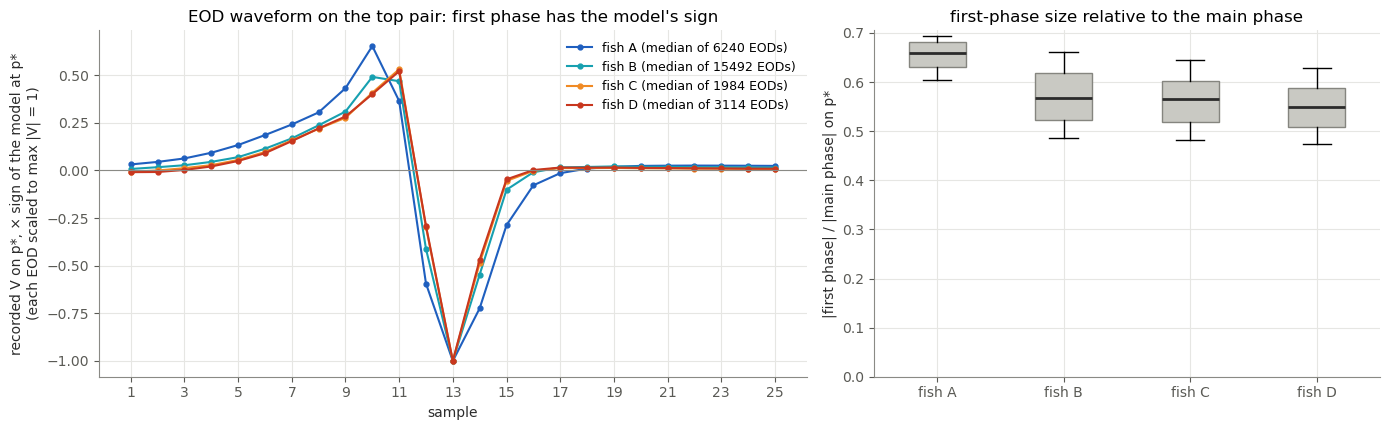

median |first| / |main| per fish: {'A': 0.659, 'B': 0.569, 'C': 0.565, 'D': 0.549}


In [2]:
# recorded waveform on p*, oriented so that the model's sign is positive: the first phase (t1) has the model sign
fig, axs = plt.subplots(1, 2, figsize=(14, 4.4), gridspec_kw=dict(width_ratios=[1.4, 1]))
x = np.arange(1, 26)
for f in LET:
    k = FI == LET.index(f); wn = W[k] / np.abs(W[k]).max(1, keepdims=True)
    axs[0].plot(x, np.median(wn, 0), '-o', ms=3.5, color=FISH_COL[f], label=f'fish {f} (median of {k.sum()} EODs)')
axs[0].axhline(0, color='#8a8a85', lw=0.8)
axs[0].set(xlabel='sample', ylabel='recorded V on p*, × sign of the model at p*\n(each EOD scaled to max |V| = 1)',
           title='EOD waveform on the top pair: first phase has the model\'s sign', xticks=x[::2])
axs[0].legend(frameon=False, fontsize=9)
ratio = np.abs(R[ii, pk]) / np.abs(W[ii, T12[:, 1]])
axs[1].boxplot([ratio[FI == j] for j in range(4)], whis=(5, 95), showfliers=False, patch_artist=True,
               boxprops=dict(facecolor='#C9C9C3', edgecolor='#85857F'), medianprops=dict(color='#2b2b2b', lw=2))
axs[1].set(xticks=range(1, 5), xticklabels=[f'fish {f}' for f in LET], ylim=(0, None), ylabel='|first phase| / |main phase| on p*',
           title='first-phase size relative to the main phase')
plt.tight_layout(); fig.savefig(f'{OUT}/waveform_first_phase.png', dpi=110, bbox_inches='tight'); plt.show()
print('median |first| / |main| per fish:', {f: round(float(np.median(ratio[FI == j])), 3) for j, f in enumerate(LET)})

## 4. Gains on all five videos, and on each video alone

In [3]:
def fit(R, M, fi, iters=200):
    '''min sum (R - a[fi] b M)^2, a, b >= 0 (ALS, each step the exact constrained minimiser); geometric mean of b = 1.'''
    a, b = np.ones(4), np.ones(10)
    for _ in range(iters):
        X = M * b
        a = np.array([max(0.0, (R[fi == f] * X[fi == f]).sum() / (X[fi == f] ** 2).sum()) if (fi == f).any() else np.nan for f in range(4)])
        Y = M * np.nan_to_num(a)[fi, None]; b = np.maximum(0.0, (R * Y).sum(0) / np.maximum((Y ** 2).sum(0), 1e-300))
    c = np.exp(np.mean(np.log(b[b > 0])))
    return a * c, b / c

def fit_g0(R, M, fi):
    X = L[fi, None] ** E * M
    return max(0.0, (R * X).sum() / (X ** 2).sum())

a_all, b_all = fit(R, M, FI); g0_all = fit_g0(R, M, FI)
rng = np.random.default_rng(0)
boot = np.array([np.r_[fit(R[i], M[i], FI[i], iters=60)] for i in (rng.integers(0, len(R), len(R)) for _ in range(200))])
lo, hi = np.percentile(boot, [2.5, 97.5], axis=0)
MIN_N = 20                                                                     # a fish's gain on one video needs >= 20 EODs
per_video = {}
for t in RECS:
    k = V == t; a, b = fit(R[k], M[k], FI[k])
    n = np.array([(FI[k] == j).sum() for j in range(4)]); a = np.where(n >= MIN_N, a, np.nan)
    per_video[t] = np.r_[a, b]
names = [f'fish {f}' for f in LET] + [f'pair {p}' for p in range(1, 11)]
G = pd.DataFrame({'gain (all videos)': np.r_[a_all, b_all], '95% low': lo, '95% high': hi,
                  **{f'{t} alone': per_video[t] for t in RECS}}, index=names)
G['videos: min'] = G[[f'{t} alone' for t in RECS]].min(1); G['videos: max'] = G[[f'{t} alone' for t in RECS]].max(1)
G['isolated EODs'] = [int((FI == j).sum()) for j in range(4)] + [int((PSTAR == p).sum()) for p in range(1, 11)]
G.to_csv(f'{OUT}/gains_all_and_per_video.csv')
display(G.round(3))
print(f'global fit: g0 = {g0_all:.4f}')

,gain (all videos),95% low,95% high,05_52_55 alone,06_52_55 alone,11_12_57 alone,15_16_23 alone,19_16_25 alone,videos: min,videos: max,isolated EODs
fish A,0.297,0.296,0.299,0.292,0.329,NaN,0.303,0.271,0.271,0.329,6240
fish B,0.166,0.165,0.167,0.135,0.115,0.154,0.180,0.179,0.115,0.180,15492
fish C,0.250,0.247,0.253,0.248,0.273,NaN,0.261,0.407,0.248,0.407,1984
fish D,0.228,0.226,0.231,0.223,0.246,0.253,0.181,0.156,0.156,0.253,3114
pair 1,0.952,0.946,0.958,0.870,0.900,1.044,0.974,1.041,0.870,1.044,4758
pair 2,0.744,0.738,0.749,0.845,1.051,1.088,0.691,0.524,0.524,1.088,6312
pair 3,0.787,0.778,0.795,0.785,0.876,0.776,0.714,1.153,0.714,1.153,2852
pair 4,0.869,0.862,0.876,0.887,0.702,0.589,0.876,0.930,0.589,0.930,1070
pair 5,1.085,1.077,1.094,1.092,1.205,1.138,1.095,1.080,1.080,1.205,2401
pair 6,1.339,1.331,1.348,1.301,1.221,1.138,1.306,1.327,1.138,1.327,2577


global fit: g0 = 0.1123


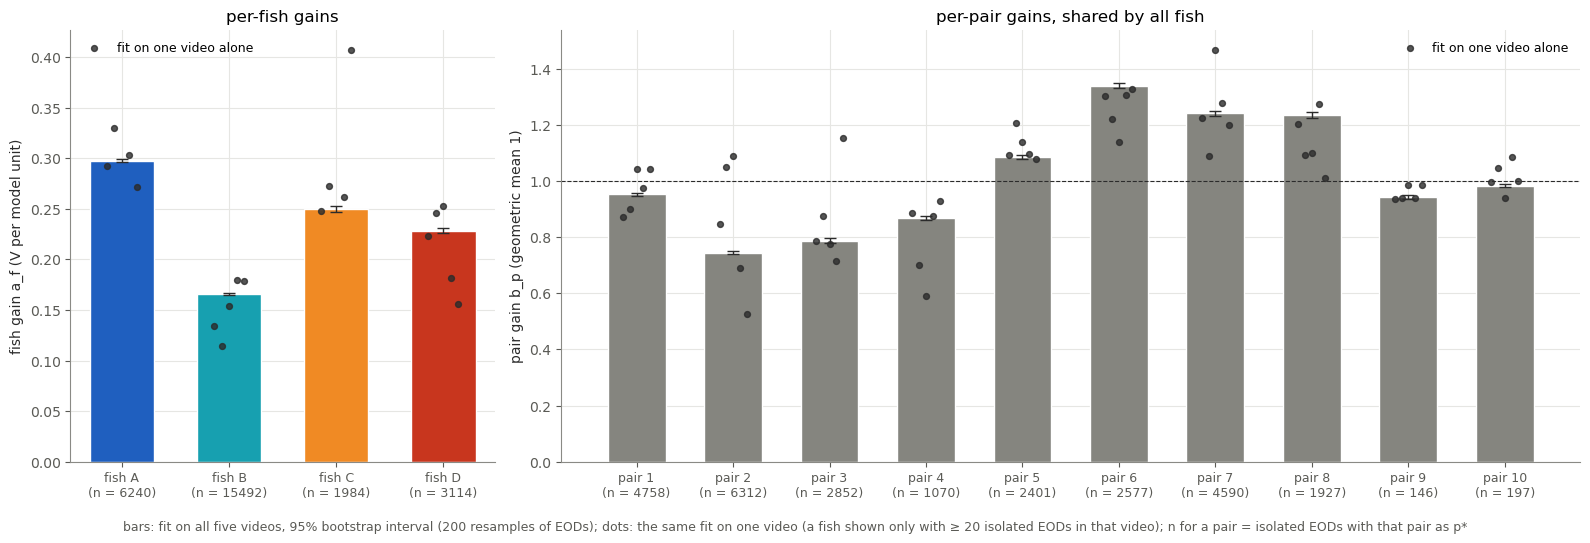

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(16, 5.2), gridspec_kw=dict(width_ratios=[1, 2.4]))
for ax, sel, ylab, title in [(axs[0], names[:4], 'fish gain a_f (V per model unit)', 'per-fish gains'),
                             (axs[1], names[4:], 'pair gain b_p (geometric mean 1)', 'per-pair gains, shared by all fish')]:
    x = np.arange(len(sel)); d = G.loc[sel]
    cols = [FISH_COL[s[-1]] for s in sel] if sel[0].startswith('fish') else ['#85857F'] * len(sel)
    ax.bar(x, d['gain (all videos)'], 0.6, color=cols, edgecolor='white')
    ax.errorbar(x, d['gain (all videos)'], yerr=[d['gain (all videos)'] - d['95% low'], d['95% high'] - d['gain (all videos)']],
                fmt='none', color='#2b2b2b', capsize=4, lw=1)
    for j, t in enumerate(RECS):
        ax.scatter(x + (j - 2) * 0.07, d[f'{t} alone'], s=18, color='#2b2b2b', zorder=3, alpha=0.8, label='fit on one video alone' if j == 0 else None)
    if sel[0].startswith('pair'): ax.axhline(1, color='#2b2b2b', lw=0.8, ls='--')
    ax.set_xticks(x); ax.set_xticklabels([f'{s}\n(n = {n})' for s, n in zip(sel, d['isolated EODs'])], fontsize=9)
    ax.set(ylabel=ylab, title=title, ylim=(0, None)); ax.legend(frameon=False, fontsize=9)
fig.text(0.5, -0.03, 'bars: fit on all five videos, 95% bootstrap interval (200 resamples of EODs); dots: the same fit on one video '
         f'(a fish shown only with ≥ {MIN_N} isolated EODs in that video); n for a pair = isolated EODs with that pair as p*',
         ha='center', fontsize=9, color='#5a5a55')
plt.tight_layout(); fig.savefig(f'{OUT}/gains_all_and_per_video.png', dpi=110, bbox_inches='tight'); plt.show()

### Where the pair gains are in the tank

Each pair drawn between its two electrodes (+ filled, − open), coloured by its gain (blue below 1, orange above 1, grey at 1).

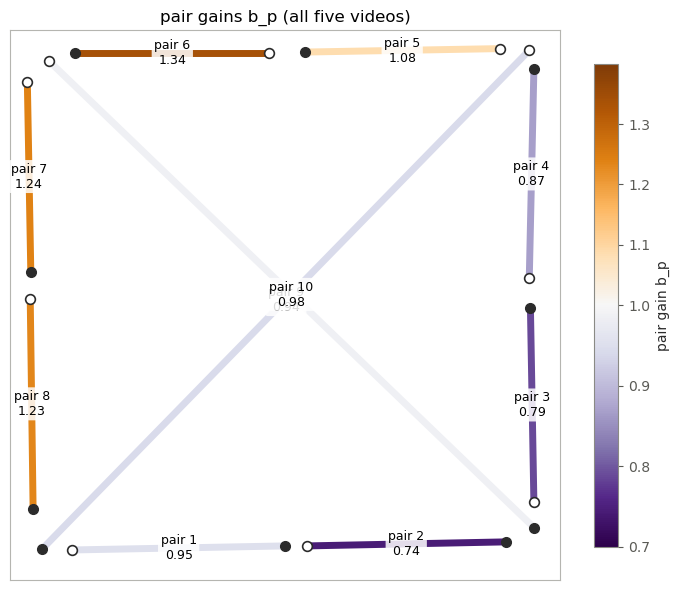

In [5]:
fig, ax = plt.subplots(figsize=(7.2, 7.2))
norm = TwoSlopeNorm(vmin=min(b_all.min(), 0.7), vcenter=1.0, vmax=max(b_all.max(), 1.4))
cmap = plt.get_cmap('PuOr_r')
for _, e in EL.iterrows():
    pp = (e.x1, e.y1) if str(e.pol1).strip() == '+' else (e.x2, e.y2); mm_ = (e.x2, e.y2) if str(e.pol1).strip() == '+' else (e.x1, e.y1)
    b = b_all[int(e.pair) - 1]
    ax.plot([pp[0], mm_[0]], [pp[1], mm_[1]], color=cmap(norm(b)), lw=5, solid_capstyle='round', zorder=1)
    ax.plot(*pp, 'o', ms=7, color='#2b2b2b', zorder=3); ax.plot(*mm_, 'o', ms=7, mfc='white', mec='#2b2b2b', mew=1.2, zorder=3)
    mx, my = (pp[0] + mm_[0]) / 2, (pp[1] + mm_[1]) / 2
    ax.text(mx, my, f'pair {int(e.pair)}\n{b:.2f}', fontsize=9, ha='center', va='center', zorder=4,
            bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='none', alpha=0.85))
ax.set(xlim=(-20, P + 20), ylim=(P + 20, -20), aspect='equal', xticks=[], yticks=[], title='pair gains b_p (all five videos)')
for sp in ax.spines.values(): sp.set_visible(True); sp.set_color('#b5b5b0')
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap); fig.colorbar(sm, ax=ax, shrink=0.7, label='pair gain b_p')
ax.grid(False)
plt.tight_layout(); fig.savefig(f'{OUT}/pair_gains_tank_map.png', dpi=110, bbox_inches='tight'); plt.show()

## 5. Does it predict a new video? Fit on four videos, test on the fifth

Errors on the same scale, $\lVert r - \hat r\rVert / \max|r|$, for every isolated EOD of the held-out video:
- **shape only**: $\hat r = m \cdot \max|r| / \max|m|$, the prediction scaled to this EOD's own recorded peak (the two patterns each
  scaled to max |v| = 1); it uses the tested EOD's amplitude, so it is not a prediction of the voltage;
- **per-fish × per-pair**: $\hat r = a_f b_p m$, gains from the other four videos;
- **global**: $\hat r = g_0 L_f^{0.25} m$, $g_0$ from the other four videos;
- **best gain per EOD** (lower bound for any per-EOD scale): $\hat r = c_i\, m$ with $c_i = (r_i \cdot m_i)/(m_i \cdot m_i)$.

Also the quantity the fit minimises: the RMS error in volts over every held-out EOD × pair.

In [6]:
D = S[['video', 'row', 'Frame', 'emitter', 'pair p* (1-10)', 'gap (cm)']].copy()
D[SH] = np.linalg.norm(R / peak(R) - M / peak(M), axis=1)
D['best gain per EOD'] = np.linalg.norm(R - ((R * M).sum(1) / (M * M).sum(1))[:, None] * M, axis=1) / peak(R)[:, 0]
sq = {V1: np.zeros(len(R)), V2: np.zeros(len(R))}
held = []
for t in RECS:
    tr, te = V != t, V == t
    a, b = fit(R[tr], M[tr], FI[tr]); g0 = fit_g0(R[tr], M[tr], FI[tr])
    for nm, Rh in ((V1, a[FI[te], None] * b[None] * M[te]), (V2, g0 * L[FI[te], None] ** E * M[te])):
        D.loc[te, nm] = np.linalg.norm(R[te] - Rh, axis=1) / peak(R[te])[:, 0]; sq[nm][te] = ((R[te] - Rh) ** 2).sum(1)
    held.append(dict(video=t, g0=g0, **{f'fish {f}': a[j] for j, f in enumerate(LET)}, **{f'pair {p + 1}': b[p] for p in range(10)}))
HELD = pd.DataFrame(held).set_index('video'); HELD.to_csv(f'{OUT}/gains_fit_without_each_video.csv')
D.to_csv(f'{OUT}/held_out_errors_per_eod.csv', index=False)
COLS = [SH, V1, V2, 'best gain per EOD']
T = D.groupby('emitter')[COLS].median(); T.loc['all'] = D[COLS].median()
T.insert(0, 'n', list(D.groupby('emitter').size()) + [len(D)])
T['RMS (V), per-fish × per-pair'] = [np.sqrt(sq[V1][FI == j].sum() / (10 * (FI == j).sum())) for j in range(4)] + [np.sqrt(sq[V1].sum() / (10 * len(R)))]
T['RMS (V), global g0 L^0.25'] = [np.sqrt(sq[V2][FI == j].sum() / (10 * (FI == j).sum())) for j in range(4)] + [np.sqrt(sq[V2].sum() / (10 * len(R)))]
T.index = [f'fish {i}' if i != 'all' else 'all fish' for i in T.index]
T.to_csv(f'{OUT}/held_out_error_summary.csv')
print('median ‖r − r̂‖ / max|r| (held out by video) and RMS error in volts:'); display(T.round(3))

median ‖r − r̂‖ / max|r| (held out by video) and RMS error in volts:


,n,shape only,per-fish × per-pair gains,global g0 × L^0.25,best gain per EOD,"RMS (V), per-fish × per-pair","RMS (V), global g0 L^0.25"
fish A,6240,0.211,0.254,0.462,0.174,0.012,0.020
fish B,15492,0.224,0.451,0.733,0.193,0.009,0.012
fish C,1984,0.193,0.384,0.445,0.164,0.010,0.012
fish D,3114,0.206,0.460,0.523,0.187,0.009,0.011
all fish,26830,0.219,0.414,0.536,0.188,0.010,0.014


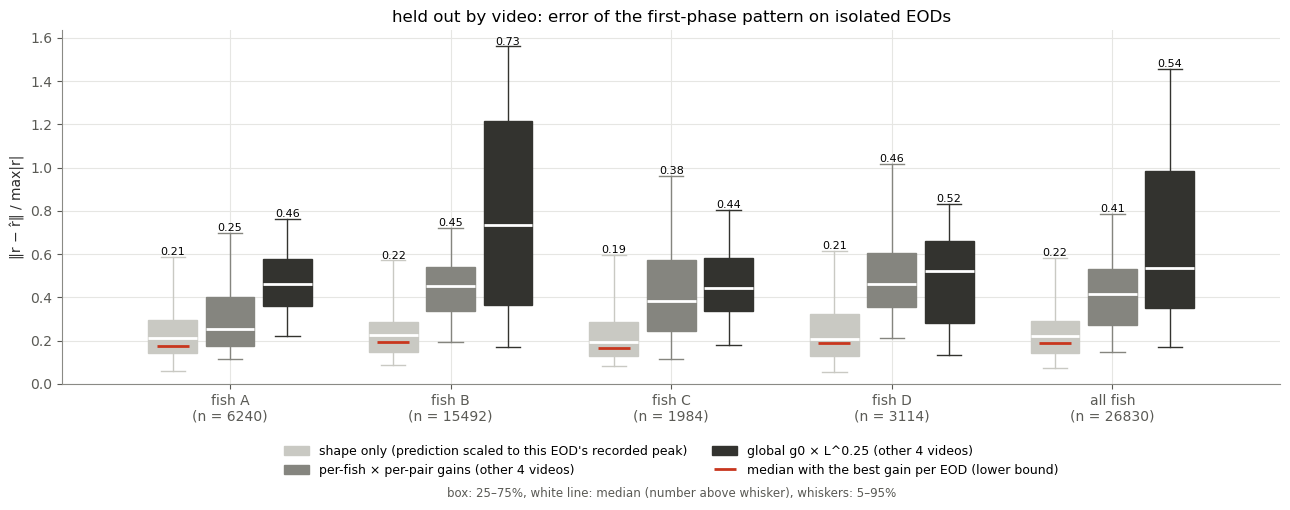

In [7]:
fig, ax = plt.subplots(figsize=(13, 5.4))
groups = list(LET) + ['all']; w = 0.26
for k, (m, c) in enumerate(COL.items()):
    data = [D.loc[D.emitter == f, m].to_numpy() if f != 'all' else D[m].to_numpy() for f in groups]
    pos = np.arange(len(groups)) + (k - 1) * w
    ax.boxplot(data, positions=pos, widths=w * 0.85, whis=(5, 95), showfliers=False, patch_artist=True,
               medianprops=dict(color='white', lw=2), whiskerprops=dict(color=c), capprops=dict(color=c), boxprops=dict(facecolor=c, edgecolor=c))
    for x, v in zip(pos, data): ax.text(x, np.percentile(v, 95), f'{np.median(v):.2f}', ha='center', va='bottom', fontsize=8)
floor = [D.loc[D.emitter == f, 'best gain per EOD'].median() if f != 'all' else D['best gain per EOD'].median() for f in groups]
ax.scatter(np.arange(len(groups)) - w, floor, marker='_', s=500, color='#C8361E', zorder=5, lw=2)
ax.set(xticks=range(len(groups)), xticklabels=[f'fish {f}\n(n = {(D.emitter == f).sum()})' if f != 'all' else f'all fish\n(n = {len(D)})' for f in groups],
       ylabel='‖r − r̂‖ / max|r|', ylim=(0, None), title='held out by video: error of the first-phase pattern on isolated EODs')
h = [Patch(color=COL[SH], label='shape only (prediction scaled to this EOD\'s recorded peak)'),
     Patch(color=COL[V1], label='per-fish × per-pair gains (other 4 videos)'),
     Patch(color=COL[V2], label='global g0 × L^0.25 (other 4 videos)'),
     Line2D([], [], marker='_', ls='', ms=16, mew=2, color='#C8361E', label='median with the best gain per EOD (lower bound)')]
ax.legend(handles=h, frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.14), ncol=2, fontsize=9)
ax.text(0.5, -0.32, 'box: 25–75%, white line: median (number above whisker), whiskers: 5–95%', transform=ax.transAxes, ha='center', fontsize=8.5, color='#5a5a55')
plt.tight_layout(); fig.savefig(f'{OUT}/held_out_error.png', dpi=110, bbox_inches='tight'); plt.show()

## 6. Is the fish gain set by body length?

Large dots: fish gains on all five videos (95% bootstrap interval) against the fish's length. Small dots: one per fish and video,
the fish gain refitted on that video's EODs with the pair gains fixed to the all-video values (only fish-videos with ≥ 20 EODs),
against the fish's length in that video. Solid line: the global fit $g_0 L^{0.25}$; dashed: a power law through the small dots
(least squares on log a vs log L).

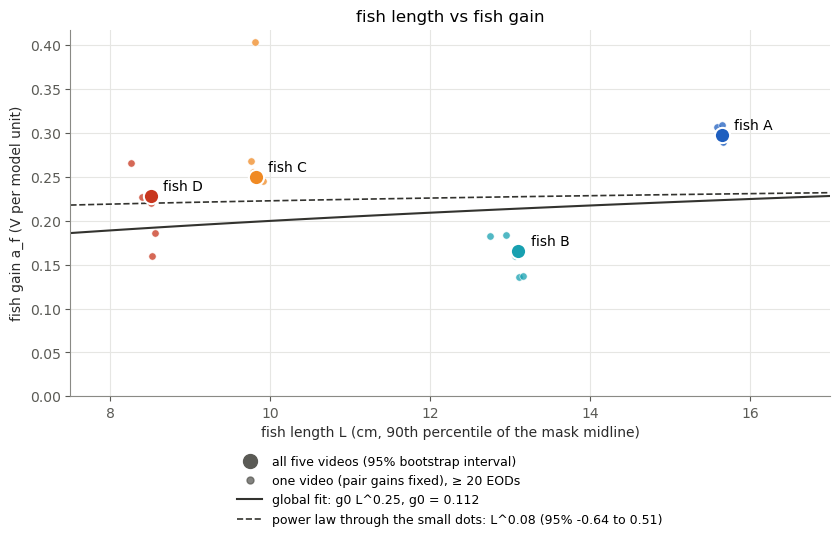

power law through the fish-video points: exponent 0.08 (95% bootstrap -0.64 to 0.51)


In [8]:
pts = []
for t in RECS:
    for j, f in enumerate(LET):
        k = (V == t) & (FI == j)
        if k.sum() < MIN_N: continue
        X = M[k] * b_all
        pts.append(dict(video=t, fish=f, L_cm=L_VIDEO.loc[f, t], a_f=max(0.0, (R[k] * X).sum() / (X ** 2).sum()), n=int(k.sum())))
PTS = pd.DataFrame(pts); PTS.to_csv(f'{OUT}/fish_gain_per_video_pairs_fixed.csv', index=False)
e_fit, logc = np.polyfit(np.log(PTS.L_cm), np.log(PTS.a_f), 1)
be = [np.polyfit(np.log(s.L_cm), np.log(s.a_f), 1)[0] for s in (PTS.sample(len(PTS), replace=True, random_state=k) for k in range(2000)) if s.fish.nunique() > 1]
e_lo, e_hi = np.percentile(be, [2.5, 97.5])
fig, ax = plt.subplots(figsize=(8.5, 5.6))
for j, f in enumerate(LET):
    p = PTS[PTS.fish == f]
    ax.scatter(p.L_cm, p.a_f, s=28, color=FISH_COL[f], alpha=0.75, edgecolor='white', lw=0.5, zorder=3)
    ax.errorbar(L[j], a_all[j], yerr=[[a_all[j] - lo[j]], [hi[j] - a_all[j]]], fmt='o', ms=11, color=FISH_COL[f], mec='white', mew=1.5, capsize=4, zorder=4)
    ax.annotate(f'fish {f}', (L[j], a_all[j]), xytext=(9, 4), textcoords='offset points', fontsize=10)
xs = np.linspace(7.5, 17, 100)
ax.plot(xs, g0_all * xs ** E, color='#33332F', lw=1.5, label=f'global fit: g0 L^0.25, g0 = {g0_all:.3f}')
ax.plot(xs, np.exp(logc) * xs ** e_fit, color='#33332F', lw=1.2, ls='--', label=f'power law through the small dots: L^{e_fit:.2f} (95% {e_lo:.2f} to {e_hi:.2f})')
ax.set(xlabel='fish length L (cm, 90th percentile of the mask midline)', ylabel='fish gain a_f (V per model unit)', ylim=(0, None), xlim=(7.5, 17),
       title='fish length vs fish gain')
h = [Line2D([], [], marker='o', ls='', ms=10, color='#5a5a55', label='all five videos (95% bootstrap interval)'),
     Line2D([], [], marker='o', ls='', ms=5, color='#5a5a55', alpha=0.75, label=f'one video (pair gains fixed), ≥ {MIN_N} EODs')]
ax.legend(handles=h + ax.get_legend_handles_labels()[0], frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.13), fontsize=9)
plt.tight_layout(); fig.savefig(f'{OUT}/fish_length_vs_gain.png', dpi=110, bbox_inches='tight'); plt.show()
print(f'power law through the fish-video points: exponent {e_fit:.2f} (95% bootstrap {e_lo:.2f} to {e_hi:.2f})')

## 7. What the gains leave: the size of each EOD

For each isolated EOD, the extra scale it needs on top of its fish and pair gains (all-video fit):
$c_i = (r_i \cdot \hat r_i) / (\hat r_i \cdot \hat r_i)$ with $\hat r_i = a_f\, b\, m_i$. If fish and pair gains explained the size of the
EODs, every $c_i$ would be 1. Below: the spread of $\log_2 c_i$ per fish, and where in the tank the EODs with large or small $c_i$
are (midline centre of the emitting fish).

,10%,25%,50%,75%,90%,90% / 10%
fish A,0.79,0.88,0.98,1.09,1.23,1.56
fish B,0.75,0.81,0.92,1.11,1.27,1.70
fish C,0.75,0.85,0.97,1.13,1.35,1.80
fish D,0.64,0.77,0.96,1.44,1.65,2.59


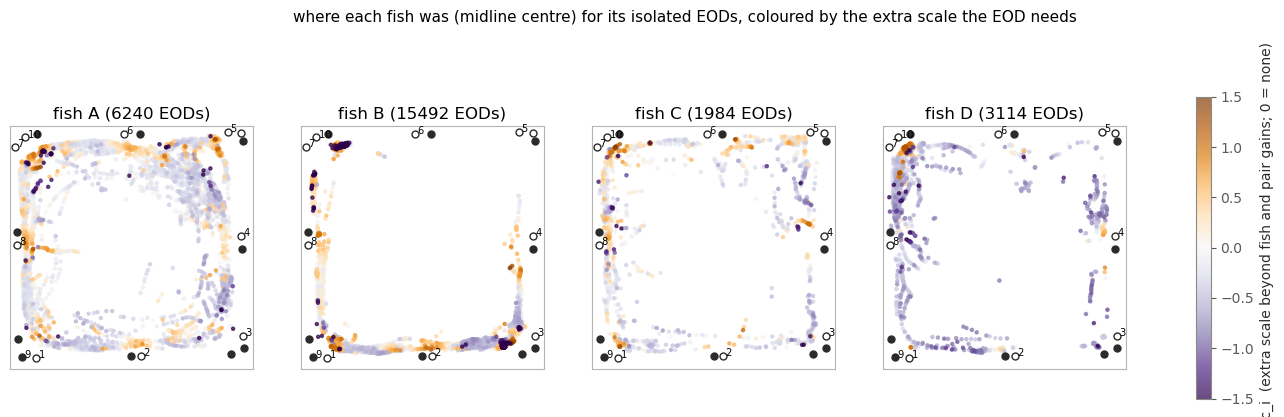

In [9]:
RH = a_all[FI, None] * b_all[None] * M
C = (R * RH).sum(1) / (RH * RH).sum(1); D['extra scale c_i'] = C
lc = np.log2(np.clip(C, 1e-3, None))
q = pd.DataFrame({f'fish {f}': np.percentile(C[FI == j], [10, 25, 50, 75, 90]) for j, f in enumerate(LET)}, index=['10%', '25%', '50%', '75%', '90%']).T
q['90% / 10%'] = q['90%'] / q['10%']; display(q.round(2)); q.to_csv(f'{OUT}/extra_scale_per_eod_quantiles.csv')
fig, axs = plt.subplots(1, 4, figsize=(18, 4.9))
norm = TwoSlopeNorm(vmin=-1.5, vcenter=0, vmax=1.5); cmap = plt.get_cmap('PuOr_r')
for ax, (j, f) in zip(axs, enumerate(LET)):
    k = FI == j; o = np.argsort(np.abs(lc[k]))
    sc = ax.scatter(CEN[k][o, 1], CEN[k][o, 0], c=lc[k][o], cmap=cmap, norm=norm, s=5, alpha=0.7)
    for _, e in EL.iterrows():
        for (x_, y_), filled in (((e.x1, e.y1), str(e.pol1).strip() == '+'), ((e.x2, e.y2), str(e.pol2).strip() == '+')):
            ax.plot(x_, y_, 'o', ms=5, mfc='#2b2b2b' if filled else 'white', mec='#2b2b2b', mew=1)
        ax.text(e.x1, e.y1, f' {int(e.pair)}', fontsize=7)
    ax.set(xlim=(-10, P + 10), ylim=(P + 10, -10), aspect='equal', xticks=[], yticks=[], title=f'fish {f} ({k.sum()} EODs)')
    for sp in ax.spines.values(): sp.set_visible(True); sp.set_color('#b5b5b0')
    ax.grid(False)
fig.colorbar(sc, ax=axs, shrink=0.8, label='log2 c_i  (extra scale beyond fish and pair gains; 0 = none)')
fig.suptitle('where each fish was (midline centre) for its isolated EODs, coloured by the extra scale the EOD needs', fontsize=11)
fig.savefig(f'{OUT}/extra_scale_map.png', dpi=110, bbox_inches='tight'); plt.show()